<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-10/lab-060-cavity-checks.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

# Lab 060. Cavity feedback and numerical checks
We study one driven lossy cavity mode and a noisy photon-number meter. The initial state is vacuum. Time is measured in units of $1/\kappa$, with the photon loss rate $\kappa=1$, and drive strengths in units of $\kappa$. The reward is the one-photon probability, averaged over 100 decisions spaced by $0.05/\kappa$. The controller receives only recent readings and chooses a drive; the simulator computes the reward from its conditional state. This notebook trains no agent. We repeat the constant-drive and threshold-rule selection of Lab 053, with the same model, on independent validation and test trajectories.

The drive Hamiltonian is $i\varepsilon(a^\dagger-a)$. A physics substep applies its unitary, then samples the loss Kraus operators $K_0=\sqrt{I-\kappa\,dt\,n}$ and $K_1=\sqrt{\kappa\,dt}\,a$. The latter construction is first order in time and requires $\kappa\,dt\,(N_{\rm cut}-1)\le1$. At each decision the meter samples $x=n+\sigma\xi$ and updates amplitudes by $\exp[-(x-n)^2/(4\sigma^2)]$, followed by normalisation.

We keep the decision interval and meter noise per reading fixed while refining physics substeps. Changing the noise per reading changes both available information and measurement backaction. It is a change of physical measurement model.

Run in order with NumPy, SciPy and Matplotlib.

In [1]:
import json,time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm
OUT=Path('classroom_results');OUT.mkdir(exist_ok=True)
started=time.perf_counter()
def simulate(seed,drive=.75,window=4,threshold=.5,feedback=False,ncut=10,dt_s=.01,sigma=1.,batch=256):
    rng=np.random.default_rng(seed);n=np.arange(ncut);a=np.diag(np.sqrt(n[1:]),1)
    dt=.05;nsub=round(dt/dt_s)
    assert np.isclose(nsub*dt_s,dt) and dt_s*(ncut-1)<=1
    amplitudes=np.zeros((batch,ncut));amplitudes[:,0]=1
    history=np.zeros((batch,window));U=expm(drive*dt_s*(a.T-a))
    k0=np.sqrt(1-dt_s*n);results=[];edge=0.
    for t in range(100):
        on=history.mean(1)<threshold if feedback else np.ones(batch,bool)
        for _ in range(nsub):
            driven=amplitudes@U.T
            amplitudes=np.where(on[:,None],driven,amplitudes)
            jump=np.sqrt(dt_s)*(amplitudes@a.T)
            probability=(jump**2).sum(1)
            assert np.all(probability>=0) and np.all(probability<=1+1e-10)
            use_jump=rng.random(batch)<probability
            amplitudes=np.where(use_jump[:,None],jump,amplitudes*k0)
            amplitudes/=np.linalg.norm(amplitudes,axis=1,keepdims=True)
        probs=amplitudes**2;u=rng.random(batch)
        drawn=(u[:,None]>np.cumsum(probs,axis=1)).sum(1)
        assert np.all(drawn<ncut)
        reading=drawn+sigma*rng.normal(size=batch)
        amplitudes*=np.exp(-(reading[:,None]-n)**2/(4*sigma**2))
        amplitudes/=np.linalg.norm(amplitudes,axis=1,keepdims=True)
        history=np.concatenate([history[:,1:],reading[:,None]],1)
        results.append(amplitudes[:,1]**2)
        edge=max(edge,float(np.max(np.sum(amplitudes[:,-2:]**2,axis=1))))
    rewards=np.array(results).T;episode=rewards.mean(1)
    return {'mean':float(episode.mean()),'SE':float(episode.std(ddof=1)/np.sqrt(batch)),
            'max_edge_population':edge,'time_curve':rewards.mean(0).tolist()}
print('Quantum trajectory model ready')

Quantum trajectory model ready


## Validation and held-out evaluation
A constant drive applies the same $\varepsilon$ at every decision. A threshold rule applies the drive $\varepsilon$ while the mean of the last $m$ readings is below the threshold $x_{\rm th}$ and otherwise turns it off. We scan the constant drives $\varepsilon\in\{0.5,0.75,1,1.35,2\}$ and the rules with the two strongest drives $2\kappa$ and $4\kappa$, the windows $m\in\{1,2,4,6,10,15,20\}$ and the thresholds $x_{\rm th}\in\{0.3,0.4,\dots,0.8\}$. The windows 15 and 20 extend the grid of Lab 053, so that an optimum at its edge would be visible. Each setting is scored on 2000 validation trajectories with a 32-level cutoff for constant drives and 12 levels for rules, and the tables print the mean, its standard error and the largest population of the two highest levels. The selected settings are then evaluated on 10,000 fresh test trajectories, with 32 levels for the constant drive and 16 for the rule.

Constant drive validation (2000 trajectories, 32 levels)
  eps=0.50  mean 0.0976  SE 0.0027  max edge 3.0e-231
  eps=0.75  mean 0.1681  SE 0.0029  max edge 1.3e-205
  eps=1.00  mean 0.2261  SE 0.0027  max edge 4.6e-172
  eps=1.35  mean 0.2575  SE 0.0022  max edge 9.1e-128
  eps=2.00  mean 0.2205  SE 0.0019  max edge 3.0e-49
Threshold rule validation, drive 2: rows window m, columns threshold [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
  m= 1  0.320 0.338 0.356 0.371 0.380 0.385
  m= 2  0.342 0.371 0.392 0.407 0.417 0.424
  m= 4  0.376 0.410 0.434 0.448 0.451 0.451
  m= 6  0.393 0.428 0.450 0.461 0.461 0.453
  m=10  0.411 0.438 0.453 0.458 0.449 0.434
  m=15  0.405 0.423 0.429 0.425 0.421 0.408
  m=20  0.390 0.398 0.401 0.399 0.391 0.381
Threshold rule validation, drive 4: rows window m, columns threshold [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
  m= 1  0.475 0.469 0.457 0.440 0.422 0.402
  m= 2  0.526 0.524 0.512 0.494 0.470 0.443
  m= 4  0.551 0.552 0.537 0.518 0.489 0.455
  m= 6  0.543 0.544 0.529 0.507 0.

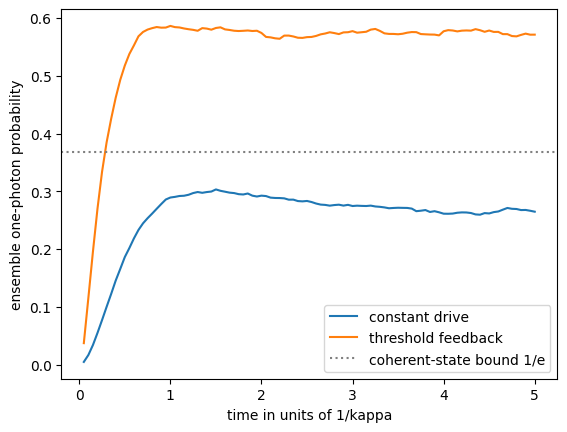

In [2]:
DRIVES=[.5,.75,1.,1.35,2.]
constants={e:simulate(600,drive=e,ncut=32,batch=2000) for e in DRIVES}
print('Constant drive validation (2000 trajectories, 32 levels)')
for e,r in constants.items():print(f"  eps={e:4.2f}  mean {r['mean']:.4f}  SE {r['SE']:.4f}  max edge {r['max_edge_population']:.1e}")
eps=max(constants,key=lambda e:constants[e]['mean'])
WINDOWS=[1,2,4,6,10,15,20];THRESHOLDS=[.3,.4,.5,.6,.7,.8]
rules={(d,m,x):simulate(601,drive=d,window=m,threshold=x,feedback=True,ncut=12,batch=2000)
       for d in [2.,4.] for m in WINDOWS for x in THRESHOLDS}
for d in [2.,4.]:
    print(f'Threshold rule validation, drive {d:g}: rows window m, columns threshold',THRESHOLDS)
    for m in WINDOWS:print(f'  m={m:2d} ',' '.join(f"{rules[d,m,x]['mean']:.3f}" for x in THRESHOLDS))
print('largest edge population over all rules',f"{max(r['max_edge_population'] for r in rules.values()):.1e}",
      '; validation SE about',round(float(np.mean([r['SE'] for r in rules.values()])),4))
drive,w,th=max(rules,key=lambda k:rules[k]['mean'])
const=simulate(1600,drive=eps,ncut=32,batch=10000)
rule=simulate(1601,drive=drive,window=w,threshold=th,feedback=True,ncut=16,batch=10000)
print('Best tested constant drive',eps,'test mean and SE',round(const['mean'],4),round(const['SE'],4))
print('Best tested rule, drive, window and threshold',drive,w,th,'test mean and SE',round(rule['mean'],4),round(rule['SE'],4))
print('Lab 053 for comparison: constant 1.35 gives 0.258 (exact); rule m=4, x_th=0.4 at drive 4 gives 0.549-0.550')
plt.plot(np.arange(1,101)*.05,const['time_curve'],label='constant drive')
plt.plot(np.arange(1,101)*.05,rule['time_curve'],label='threshold feedback')
plt.axhline(np.exp(-1),color='gray',ls=':',label='coherent-state bound 1/e')
plt.xlabel('time in units of 1/kappa');plt.ylabel('ensemble one-photon probability');plt.legend();plt.show()

## Timestep, cutoff and observation sensitivity
The following checks use the selected threshold rule, frozen after validation, and 10,000 trajectories per setting. The timestep scan refines the physics substep $dt$ at fixed meter timing. Its settings use independent seeds, so their differences can be compared with the printed standard errors.

The cutoff scans reuse one seed for all cutoffs. These are paired comparisons with common random numbers. While the highest levels are almost empty the trajectories nearly coincide, and the printed paired difference to the largest cutoff measures the truncation error directly. The standard error of a single mean is the wrong yardstick for that difference. The edge population shows how close each cutoff comes to the truncation boundary.

The window and noise scans use the fixed rule with independent seeds. Comparisons with the neural agent belong to Lab 053.

In [3]:
checks={};B=10000
for k,dt_s in enumerate([.01,.005,.0025,.00125]):
    checks[f'dt={dt_s}']=simulate(1700+k,drive=drive,window=w,threshold=th,feedback=True,ncut=12,dt_s=dt_s,batch=B)
paired={}
for ncut in [8,10,12,16]:
    checks[f'rule cutoff={ncut}']=simulate(1800,drive=drive,window=w,threshold=th,feedback=True,ncut=ncut,batch=B)
for ncut in [16,24,32]:
    checks[f'constant cutoff={ncut}']=simulate(1850,drive=eps,ncut=ncut,batch=B)
for ncut in [8,10,12]:paired[f'rule cutoff {ncut} minus 16']=checks[f'rule cutoff={ncut}']['mean']-checks['rule cutoff=16']['mean']
for ncut in [16,24]:paired[f'constant cutoff {ncut} minus 32']=checks[f'constant cutoff={ncut}']['mean']-checks['constant cutoff=32']['mean']
for k,sigma in enumerate([.5,1.,2.]):
    checks[f'noise={sigma}']=simulate(1900+k,drive=drive,window=w,threshold=th,feedback=True,ncut=12,sigma=sigma,batch=B)
for k,window in enumerate([1,4,10,20]):
    checks[f'window={window}']=simulate(2000+k,drive=drive,window=window,threshold=th,feedback=True,ncut=12,batch=B)
for label,result in checks.items():
    print(f"{label:20s} mean {result['mean']:.4f}  SE {result['SE']:.4f}  max edge population {result['max_edge_population']:.2e}")
for label,diff in paired.items():print(f'paired difference, {label}: {diff:.1e}')
summary={'experiment':'constant and threshold cavity diagnostics, no trained agent',
         'constant_validation':{str(e):r['mean'] for e,r in constants.items()},
         'rule_validation':{f'{d},{m},{x}':r['mean'] for (d,m,x),r in rules.items()},
         'constant_drive':eps,'rule_drive':drive,'rule_window':w,'rule_threshold':th,
         'constant_test':const,'rule_test':rule,'checks':checks,'paired_cutoff_differences':paired,
         'runtime_seconds':time.perf_counter()-started}
(OUT/'lab060_results.json').write_text(json.dumps(summary,indent=2))
print('Runtime seconds',round(summary['runtime_seconds'],1))

dt=0.01              mean 0.5500  SE 0.0011  max edge population 4.11e-11
dt=0.005             mean 0.5482  SE 0.0011  max edge population 1.94e-13
dt=0.0025            mean 0.5478  SE 0.0011  max edge population 1.84e-13
dt=0.00125           mean 0.5508  SE 0.0011  max edge population 3.66e-13
rule cutoff=8        mean 0.5487  SE 0.0011  max edge population 9.34e-02
rule cutoff=10       mean 0.5487  SE 0.0011  max edge population 8.25e-05
rule cutoff=12       mean 0.5487  SE 0.0011  max edge population 5.28e-10
rule cutoff=16       mean 0.5487  SE 0.0011  max edge population 1.75e-26
constant cutoff=16   mean 0.2575  SE 0.0010  max edge population 9.47e-03
constant cutoff=24   mean 0.2575  SE 0.0010  max edge population 2.32e-39
constant cutoff=32   mean 0.2575  SE 0.0010  max edge population 2.41e-109
noise=0.5            mean 0.5543  SE 0.0016  max edge population 1.48e-36
noise=1.0            mean 0.5501  SE 0.0011  max edge population 1.22e-12
noise=2.0            mean 0.4236  SE 

## Interpreting the numerical checks
The validation reproduces the selection of Lab 053 with independent trajectories. The best tested constant drive is $\varepsilon=1.35\kappa$. Its test mean $0.2568\pm0.0010$ agrees with the exact density-matrix value 0.258 of Lab 053 within about one standard error. With the drive $4\kappa$ the best rule uses $m=4$ and $x_{\rm th}=0.4$, as in Lab 053, and reaches $0.5495\pm0.0011$ on the test trajectories, inside the range 0.549 to 0.550 of that study, where the trained agents reach 0.557 to 0.566. The weaker drive $2\kappa$ gives at most 0.461 on validation. The selected window lies inside the extended grid. Windows of 15 and 20 readings give lower means, consistent with a long average responding late to a photon loss.

The four timestep estimates come from independent seeds and differ by at most 0.003, about two combined standard errors, with no systematic trend as $dt$ decreases. The discretisation error at $dt=0.01$ is therefore below the resolution of about 0.003 of this scan. In the paired cutoff scans the rule means agree to $4\times10^{-12}$ from 8 levels on, although at 8 levels one trajectory places up to 9% of its population on the two highest levels. The constant-drive means agree to $5\times10^{-14}$ from 16 levels on. The noise scan keeps the window and threshold selected at $\sigma=1$. A less noisy meter, $\sigma=0.5$, raises the mean slightly to 0.554, and $\sigma=2$ lowers it to 0.424. These scans concern this rule and these settings and establish no general convergence guarantee for every controller or drive.

## Student calculations
Check Kraus completeness and identify the timestep restriction. Derive the Gaussian meter update from its likelihood. Explain why changing noise changes both information and backaction. Compare timestep differences with sampling uncertainty. Explain why constant drive with this active meter is a different physical model from an unmeasured coherently driven cavity, for which the coherent-state one-photon bound is $e^{-1}$. Distinguish selecting a threshold on validation data from evaluating it on held-out data.